# Etapa 2 — Diagnóstico de la MLP y comparación con CNN

Este notebook analiza **corridas históricas**, sin entrenar ni importar TensorFlow/PyTorch. Complementa la entrega existente; el notebook final del Avance 4 se actualizará en la etapa 5.

## Resultado principal

La MLP A4 es una red densa de 9,660,776 parámetros. Su F1 macro es 0.0280 y exactitud 15.52%; la CNN original alcanza 0.5740 y 63.25%. La MLP predice 21 de 104 clases y concentra 85.24% de sus predicciones en cinco clases. Su bajo ajuste requiere investigar optimización y representación; estos resultados no bastan para atribuirlo a sobreajuste.

No hay nuevos entrenamientos ni nuevas métricas de inferencia sobre imágenes. Las pérdidas y métricas de train proceden de los históricos.

## 1. Contexto y método

Datos declarados: Kaggle train=12,753 y val=3,712, seed=0, RGB 112×112, x/255, batch=64. Se mantienen familias separadas: A4 DirectML/RX6700S; F TensorFlow/Metal según documentación. MLP A4 usa LR=1e-4 y paciencia 10; CNN original usa LR=1e-3 y paciencia 5. Ambas usan aumentos y dropout 0.5. Comparación descriptiva, sin aislamiento causal ni significancia estadística.

Dependencias ligeras: numpy, pandas, scipy, scikit-learn, matplotlib, nbformat e ipykernel. La inspección opcional de pesos requiere h5py, pero este notebook puede leer sus resultados registrados.

Reproducir derivados desde la raíz: `python -m scripts.analyze_mlp_avance4`. Inspección opcional: `python -m scripts.inspect_mlp_weights`. Ambos escriben solo bajo `reports/entregable_4/correcciones_etapa2/`; no entrenan.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/model.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUT = ROOT / "reports/entregable_4/correcciones_etapa2"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
manifest = json.loads((OUT / "diagnostico.json").read_text(encoding="utf-8"))
print("Commit de origen:", manifest["source_commit"])
print("Método:", manifest["purpose"])
display(manifest["local_execution_readiness"])

Commit de origen: 749ddd05febf447bf82107cb6dd4f0bcb3b60acd
Método: Stage 2: derived historical diagnostics, no new training/inference


{'configured_tfrecords': 'data/raw/tpu-getting-started/tfrecords-jpeg-224x224',
 'configured_tfrec_files': 0,
 'available_modules': {'tensorflow': False,
  'keras': False,
  'torch': False,
  'torch_directml': False},
 'external_dataset': 'Not located; a path was requested from the user'}

## 2. Fuentes y validación

Se verifican hashes de los inputs originales y scripts. Para texto se admite equivalencia LF/CRLF entre plataformas, registrada por separado; para checkpoints binarios se exige el hash exacto. Se recalculan las métricas desde las predicciones y se comprueban matrices, épocas y resúmenes. Esto no repite la inferencia del modelo sobre las imágenes.

In [2]:
from scripts.analyze_mlp_avance4 import SPECS, validate_saved_predictions
normalized_matches = 0
for relative, expected in manifest["sources_sha256"].items():
    data = (ROOT / relative).read_bytes()
    if hashlib.sha256(data).hexdigest() != expected:
        normalized = hashlib.sha256(data.replace(b"\r\n", b"\n")).hexdigest()
        assert normalized == manifest["text_sources_lf_sha256"].get(relative), relative
        normalized_matches += 1
histories, summaries = {}, {}
for identifier, name, family, variant, run, lr in SPECS:
    directory = ROOT / family / "runs" / variant / run
    predictions = pd.read_csv(directory / "evaluation/validation_predictions.csv")
    matrix = pd.read_csv(directory / "evaluation/confusion_matrix.csv", index_col=0).to_numpy()
    report = json.loads((directory / "eval_report.json").read_text(encoding="utf-8"))
    summary = json.loads((directory / "summary.json").read_text(encoding="utf-8"))
    history = pd.read_csv(directory / "history.csv")
    validate_saved_predictions(predictions, matrix, report, summary, history)
    histories[identifier], summaries[identifier] = history, summary
print(f"{len(SPECS)} corridas coherentes; {len(manifest['sources_sha256'])} hashes comprobados.")
print("Coincidencias por normalización LF/CRLF:", normalized_matches)

5 corridas coherentes; 43 hashes comprobados.
Coincidencias por normalización LF/CRLF: 0


## 3. Comparación de modelos

Exactitud y F1 pertenecen al mismo checkpoint seleccionado por F1, no a máximos elegidos por separado. La MLP del reporte final es otra corrida: no se combina con la MLP A4 ni se presenta como repetición equivalente.

In [3]:
results = pd.read_csv(OUT / "comparacion_modelos.csv")
display(results[["experiment_id", "parameters", "checkpoint_epoch", "epochs_run", "initial_lr",
                 "accuracy", "f1_macro", "predicted_classes", "zero_f1_classes"]].round(6))
a4 = results.set_index("experiment_id")
print("Cambio de exactitud MLP → CNN original (pp):",
      100*(a4.loc["A4_CNN_original", "accuracy"] - a4.loc["A4_MLP_lr1e4", "accuracy"]))
print("Control analítico de clase mayoritaria elegida por train:",
      a4.loc["A4_MLP_lr1e4", ["majority_control_label", "majority_control_accuracy", "majority_control_f1"]].to_dict())

,experiment_id,parameters,checkpoint_epoch,epochs_run,initial_lr,accuracy,f1_macro,predicted_classes,zero_f1_classes
0,A4_MLP_lr1e4,9660776,77,87,0.0001,0.155172,0.028013,21,87
1,A4_CNN_original,480936,53,58,0.0010,0.632543,0.573954,102,4
2,A4_CNN_deep,1218600,46,51,0.0010,0.622306,0.550151,102,4
3,A4_CNN_AdamW,480936,61,73,0.0010,0.644397,0.574474,103,6
4,F_MLP_AdamW,9660776,62,74,0.0001,0.143588,0.017773,11,93


Cambio de exactitud MLP → CNN original (pp): 47.737068965517246
Control analítico de clase mayoritaria elegida por train: {'majority_control_label': 67, 'majority_control_accuracy': 0.0614224137931034, 'majority_control_f1': 0.0011128465443186}


## 4. Curvas MLP frente a CNN

Train online incluye actualizaciones, aumentos y dropout. Validación se mide sin ellos. Por eso su diferencia puntual no es una brecha limpia de generalización. Se conserva una escala común por métrica y se muestra el checkpoint seleccionado.

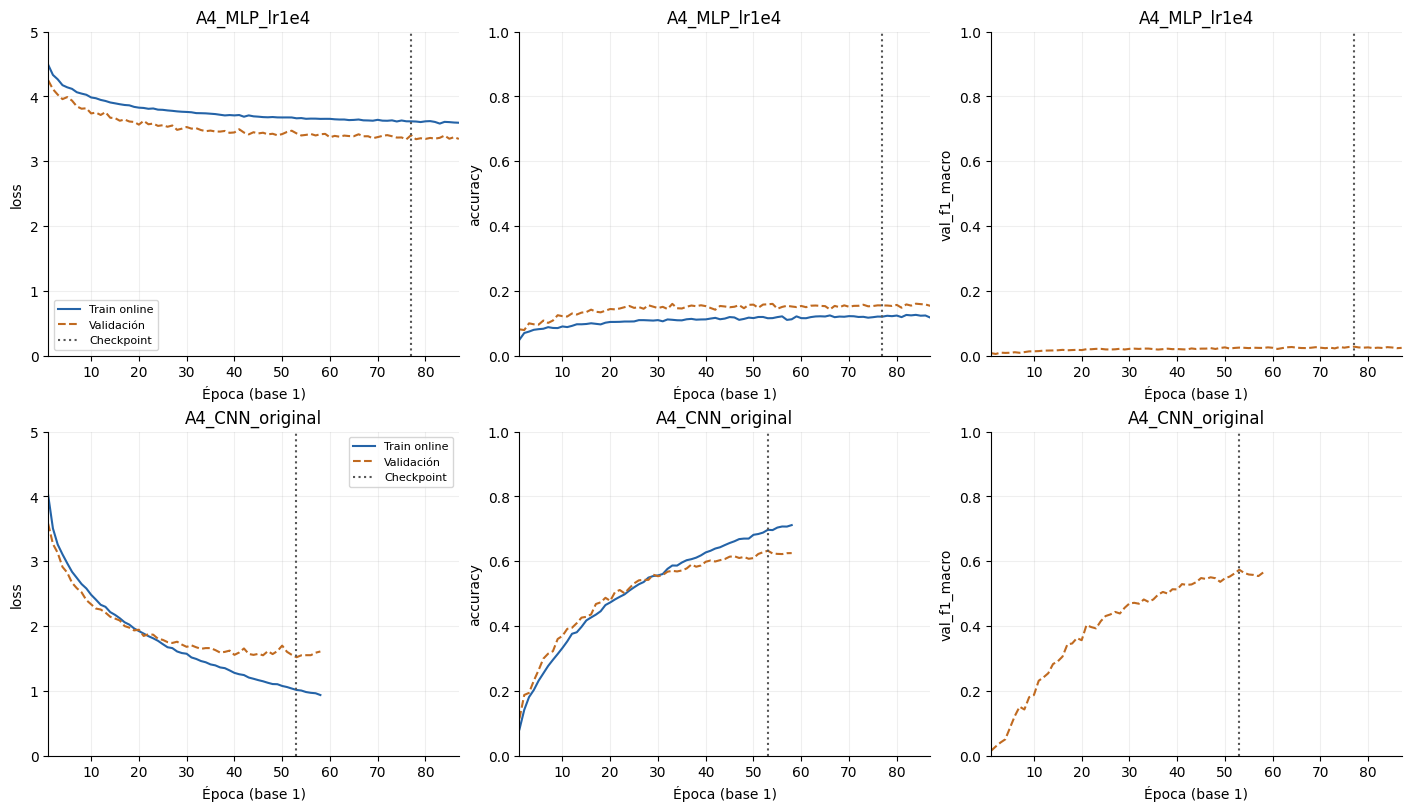

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), layout="constrained")
for i, identifier in enumerate(["A4_MLP_lr1e4", "A4_CNN_original"]):
    history, summary = histories[identifier], summaries[identifier]
    for ax, metric in zip(axes[i], ["loss", "accuracy", "val_f1_macro"]):
        if metric != "val_f1_macro":
            ax.plot(history.epoch+1, history[metric], color="#2463a7", label="Train online")
            ax.plot(history.epoch+1, history["val_"+metric], color="#c06a20", ls="--", label="Validación")
        else:
            ax.plot(history.epoch+1, history[metric], color="#c06a20", ls="--", label="Validación")
        ax.axvline(summary["best_epoch"], color="#555555", ls=":", label="Checkpoint")
        ax.set(title=identifier, xlabel="Época (base 1)", ylabel=metric,
               xlim=(1,87), ylim=(0,5) if metric=="loss" else (0,1))
        ax.grid(alpha=.2)
    axes[i,0].legend(fontsize=8)
plt.show()

La MLP conserva una pérdida elevada y una exactitud de entrenamiento baja; no muestra el patrón de memorización fuerte que sí sugiere la CNN en la fase final. No puede medirse aquí F1 limpio de train para la MLP A4: ese dato no fue guardado.

La MLP F sí tiene evaluación histórica limpia de un subconjunto fijo de train. Su F1 train cercano a 0.0192 y F1 val cercano a 0.0178 apoyan un diagnóstico de ajuste insuficiente en esa corrida, sin trasladar su brecha a A4.

In [5]:
display(results.loc[results.experiment_id=="F_MLP_AdamW",
    ["experiment_id", "train_eval_accuracy_saved", "train_eval_f1_saved", "train_eval_loss_saved", "accuracy", "f1_macro"]])
final_history = histories["F_MLP_AdamW"]
print("LR mínimo de la MLP F:", final_history.learning_rate.min())
print("Primera época con LR mínimo:", int(final_history.loc[
    final_history.learning_rate <= final_history.learning_rate.min()*1.001, "epoch"].iloc[0])+1)

,experiment_id,train_eval_accuracy_saved,train_eval_f1_saved,train_eval_loss_saved,accuracy,f1_macro
4,F_MLP_AdamW,0.157597,0.019213,3.553175,0.143588,0.017773


LR mínimo de la MLP F: 9.999999974752427e-07
Primera época con LR mínimo: 57


## 5. Comportamiento de las predicciones

El F1 macro penaliza clases sin aciertos aunque la exactitud mejore al acertar algunas clases frecuentes. Se comparan soportes reales y predicciones de las diez clases más predichas por cada modelo; los ejes de conteos comparten escala.

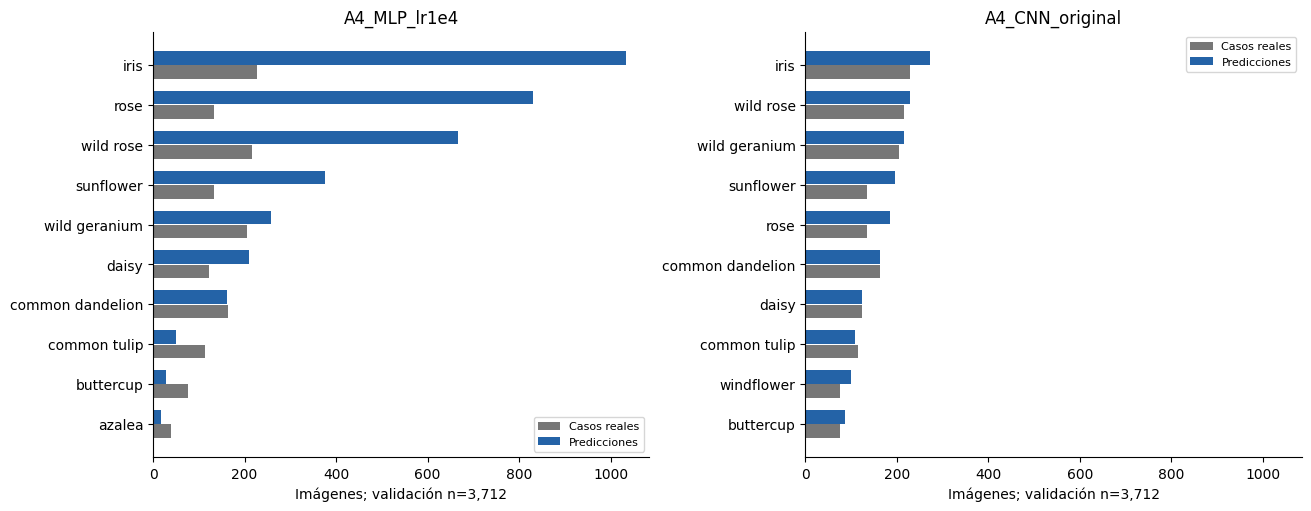

,experiment_id,top5_prediction_share,predicted_classes,zero_f1_classes
0,A4_MLP_lr1e4,0.85237,21,87
1,A4_CNN_original,0.29553,102,4
2,A4_CNN_deep,0.29310,102,4
3,A4_CNN_AdamW,0.29337,103,6
4,F_MLP_AdamW,0.85264,11,93


In [6]:
classes = pd.read_csv(OUT / "metricas_por_clase.csv")
fig, axes = plt.subplots(1,2, figsize=(13,5), layout="constrained", sharex=True)
for ax, identifier in zip(axes,["A4_MLP_lr1e4", "A4_CNN_original"]):
    selected = classes[classes.experiment_id==identifier].sort_values("predicted_count",ascending=False).head(10).iloc[::-1]
    y = np.arange(len(selected))
    ax.barh(y-.18, selected.support, height=.34, color="#777777", label="Casos reales")
    ax.barh(y+.18, selected.predicted_count, height=.34, color="#2463a7", label="Predicciones")
    ax.set_yticks(y, selected["name"])
    ax.set(title=identifier, xlabel="Imágenes; validación n=3,712")
    ax.legend(fontsize=8)
plt.show()
display(results[["experiment_id", "top5_prediction_share", "predicted_classes", "zero_f1_classes"]].round(5))

La MLP A4 predice 21 clases y deja 87 con F1 cero: cuatro de las clases que llega a predecir tampoco tienen aciertos. No es un clasificador útil de las 104 categorías, aunque supere al control mayoritario. La mediana de confianza softmax guardada es aproximadamente 7.30%; esto no es una evaluación de calibración.

## 6. Pesos y arquitectura de la MLP

Se leyeron configuración Keras y arrays HDF5 sin cargar el modelo ni ejecutar pickle. La primera capa contiene 9,634,048 parámetros (99.72% del total). Los pesos son finitos. No hay convoluciones ni pooling.

La suma de pesos entrantes negativa en muchas neuronas es una pista para comprobar activaciones y centrado con imágenes reales; no prueba por sí sola neuronas muertas. Los límites exactos para entradas en [0,1] no certifican ninguna neurona permanentemente inactiva.

In [7]:
weights = json.loads((OUT / "pesos_mlp.json").read_text(encoding="utf-8"))
weight_rows = []
for identifier, record in weights["models"].items():
    weight_rows.append({"experiment_id":identifier, "parameters":record["parameters"],
        "first_layer_percent":100*record["first_layer_parameters"]/record["parameters"],
        "negative_sum_units":record["negative_incoming_sum_with_bias_units"],
        "guaranteed_inactive_units":record["guaranteed_inactive_units_on_unit_cube"],
        "finite_weights":record["finite_weights"]})
display(pd.DataFrame(weight_rows))
print("Capas:", weights["models"]["A4_MLP_lr1e4"]["layer_types"])
print("Límite:", weights["models"]["A4_MLP_lr1e4"]["limitation"])

,experiment_id,parameters,first_layer_percent,negative_sum_units,guaranteed_inactive_units,finite_weights
0,A4_MLP_lr1e4,9660776,99.723335,252,0,True
1,A4_MLP_lr1e3_failed,9660776,99.723335,256,0,True


Capas: ['InputLayer', 'Flatten', 'Dense', 'Dropout', 'Dense']
Límite: No real images, activations, gradients or logits were evaluated. Negative column sums do not prove inactive ReLUs on real images.


## 7. Interpretación y próximos experimentos

- **Entrenamiento/optimización:** el ensayo LR=1e-3 colapsó según su registro. La referencia LR=1e-4 mejora pero no logra buen ajuste. En la MLP F, el scheduler llega al mínimo 1e-6 en la época 57; esto sugiere revisar el calendario, sin demostrar que sea la causa única.
- **Infraajuste observado:** predicciones concentradas, poca cobertura y baja calidad de ajuste. Para A4 falta evaluación limpia de train; para F sí hay evidencia histórica limpia y baja.
- **Arquitectura:** la MLP asigna pesos independientes a cada posición de píxel; la CNN usa conectividad local y comparte filtros. El pooling reduce dimensiones, y GAP resume mapas sin una gran capa sobre píxeles. Esto explica una ventaja inductiva plausible, no una prueba causal aislada.
- **No demostrado:** activaciones ReLU sobre imágenes reales, gradientes, errores de normalización efectivos en runtime, o que falten datos para cualquier MLP posible. El código sí especifica float32/255 y flatten NHWC coherente entre frameworks.

Antes de una variante nueva: recuperar TFRecords y entorno; evaluar el checkpoint en train limpio/val; revisar activaciones y gradientes; comprobar ajuste en un subconjunto real; después probar un cambio justificado (LR/calendario, centrado o activación), manteniendo partición y semilla y conservando el histórico. Ese control no sería una métrica final ni sustituiría entrenamiento completo.

## Estado de la etapa

Diagnóstico histórico reproducible completado. No se entrenó una MLP nueva porque no hay TFRecords ni frameworks de entrenamiento en el Python activo. No se usaron datos sintéticos como resultados. La siguiente etapa propuesta es recuperar la comparación conjunta de regularización ya existente; debe mantenerse separada por procedencia.